# Curve curation walkthrough: hurricane wind × real estate

**Start here.** This notebook shows how the `tropical_cyclone_wind_real_estate` curves are built: FEMA Hazus
hurricane building-loss functions, adopted exactly as published (every 5 mph from 50 to 250 mph), for the Hazus
building type and wind characteristics that match each Hazard reference building, in five terrain classes.

The companion [`01_runtime_curve_walkthrough.ipynb`](01_runtime_curve_walkthrough.ipynb) calls the curves the way
Hazard would.

Status: **noncanonical proposal**, current model **v0.2** (bound to the Hazard reference profiles r1; model v0.1 is
kept beside it). The cell documents in `docs/cells/tropical_cyclone_wind_real_estate/` are the source of truth.

In [1]:
from pathlib import Path
import json
import re
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display


def find_repo_root() -> Path:
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "docs/cells").is_dir() and (p / "scripts/reference_helpers").is_dir():
            return p
    raise RuntimeError("Run this notebook from inside the Damage_Modeling repository.")


ROOT = find_repo_root()
CELL_ID = "tropical_cyclone_wind_real_estate"
PROP = ROOT / "docs/cells" / CELL_ID / "proposed"
ARTIFACT_PATH = PROP / "tropical_cyclone_wind_real_estate__model_v0_2__docs_r1__curve_artifact.json"
REG = "tropical_cyclone_wind_real_estate__model_v0_1__docs_r1"  # tag of the cell registers (source, claims, tiers, decisions)
OUT = ROOT / "notebooks/tropical_cyclone_wind/real_estate/outputs"
OUT.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "scripts/reference_helpers"))

pd.set_option("display.max_colwidth", 160)
pd.set_option("display.width", 220)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

ART = json.loads(ARTIFACT_PATH.read_text())
# Replacement cost new from the Hazard reference profiles r1 (Q3 2025 Dallas prices). Illustration only:
# the artifacts withhold scenario dollars until the consumer qualifies each building value.
BUDGETS_USD = {"RE_RES_SFD_1S_SLAB": 405_000, "RE_IND_WAREHOUSE": 11_000_000, "RE_COM_OFFICE_3S_SLAB": 10_800_000}
NAMES = {"RE_RES_SFD_1S_SLAB": "House", "RE_IND_WAREHOUSE": "Warehouse", "RE_COM_OFFICE_3S_SLAB": "Office",
         "RE_COM_LOWRISE": "Retail (unbound)"}


def table(name: str) -> pd.DataFrame:
    return pd.read_csv(PROP / name)


def save(fig, name: str) -> None:
    fig.savefig(OUT / name, dpi=110, bbox_inches="tight", metadata={"Software": None})


def decision_log(path: Path) -> pd.DataFrame:
    """Decision-log rows: ID, whether JL decided it, and the decision text (shortened)."""
    rows = []
    for line in path.read_text().splitlines():
        if not line.startswith("| D-"):
            continue
        cells = [c.strip() for c in line.strip().strip("|").split(" | ")]
        text = re.sub(r"\*\*", "", cells[1])
        rows.append({"id": cells[0], "status": "JL decided" if "JL decided" in cells[1] else "proposed",
                      "decision": text if len(text) <= 240 else text[:240] + " …"})
    return pd.DataFrame(rows)


print("artifact:", ARTIFACT_PATH.relative_to(ROOT))
print(ART["cell_id"], "|", ART["semantic_damage_model_version"], "|", ART["damage_code_id"],
      "| promotion:", ART["promotion_status"], "| canonical:", ART["canonical_runtime_artifact"])
V2 = "tropical_cyclone_wind_real_estate__model_v0_2__docs_r1"  # tag of the model-v0.2 tables

artifact: docs/cells/tropical_cyclone_wind_real_estate/proposed/tropical_cyclone_wind_real_estate__model_v0_2__docs_r1__curve_artifact.json
tropical_cyclone_wind_real_estate | model v0.2 | TROPICAL_CYCLONE_WIND_REAL_ESTATE_HAZUS_SCREENING_V0_2 | promotion: proposed | canonical: False


## 1. What the cell is

One pathway (`tropical_cyclone_wind`) on the peak 3-second gust at 10 m in open terrain (mph). The terrain around
the building is a required selector (five Hazus classes): it picks the record and is never applied to the gust
as well. The Hazus loss already includes wind pressure, windborne debris and rain entering through wind damage.

In [2]:
identity = pd.DataFrame([
    {"field": "cell", "value": ART["cell_id"]},
    {"field": "damage code", "value": ART["damage_code_id"]},
    {"field": "model / docs", "value": f'{ART["semantic_damage_model_version"]} / {ART["documentation_revision"]}'},
    {"field": "lifecycle / promotion", "value": f'{ART["lifecycle_state"]} / {ART["promotion_status"]}'},
    {"field": "canonical runtime artifact", "value": ART["canonical_runtime_artifact"]},
    {"field": "model grade", "value": ART["model_grade"]},
])
display(identity)
units = pd.DataFrame([{k: u.get(k) for k in ("id", "treatment", "denominator")} for u in ART["failure_units"]])
display(units)
pathways = pd.DataFrame([{
    "pathway": p["pathway_id"],
    "axis field": p["hazard_axis"]["preferred_input_field"],
    "unit": p["hazard_axis"]["unit"],
    "valid range": p["hazard_axis"]["valid_range"],
    "selectors": ", ".join(s["field"] for s in p["selector_logic"] if s.get("required")),
    "conditioners": ", ".join(c["field"] for c in p["conditioner_logic"]) or "-",
    "records": len(p["curve_records"]),
} for p in ART["pathways"]])
display(pathways)
pw = ART["pathways"][0]
display(pd.DataFrame([{"building": NAMES[b], "selector": b, "Hazard profile": pw["reference_profile_binding"].get(b) or "(none: retail kept, unbound)",
                       "Hazus type": v["sbt"], "Hazus wbID": v["wbid"], "wind characteristics": v["wind_building_characteristics"]}
                      for b, v in pw["hazus_variants"].items()]))

,field,value
0,cell,tropical_cyclone_wind_real_estate
1,damage code,TROPICAL_CYCLONE_WIND_REAL_ESTATE_HAZUS_SCREENING_V0_2
2,model / docs,model v0.2 / docs r1
3,lifecycle / promotion,scaffold / proposed
4,canonical runtime artifact,False
5,model grade,screening_source_native_adopted_tables


,id,treatment,denominator
0,TCRE_BUILDING_STRUCTURE,primary_nonzero,"structure replacement cost new of the same reference building (no land, contents, site works or depreciation)"
1,TCRE_BUILDING_CONTENTS,withheld,contents value (deferred)


,pathway,axis field,unit,valid range,selectors,conditioners,records
0,tropical_cyclone_wind,tc_peak_gust_3s_10m_mph,mph,"[50.0, 250.0]","reference_building_id, hazus_terrain_class",-,20


,building,selector,Hazard profile,Hazus type,Hazus wbID,wind characteristics
0,House,RE_RES_SFD_1S_SLAB,re_house_1s_wood_slab,WSF1,6,"{'hazus_roof_shape': 'gable', 'hazus_secondary_water_resistance': 'no', 'hazus_roof_deck_attachment': '6d_6_12', 'hazus_roof_to_wall_connection': 'toe_nail'..."
1,Retail (unbound),RE_COM_LOWRISE,"(none: retail kept, unbound)",SECBL,1812,"{'hazus_roof_cover': 'bur', 'hazus_window_area': 'low', 'hazus_shutters': 'no', 'hazus_windborne_debris_environment': 'varies_by_direction', 'hazus_metal_de..."
2,Warehouse,RE_IND_WAREHOUSE,re_warehouse_1s_steel_slab,SPMBL,1730,"{'hazus_roof_deck_age': 'new_or_average', 'hazus_shutters': 'no', 'hazus_metal_deck_attachment': 'standard'}"
3,Office,RE_COM_OFFICE_3S_SLAB,re_office_3s_slab,SECBM,1840,"{'hazus_roof_cover': 'spm', 'hazus_window_area': 'medium', 'hazus_shutters': 'no', 'hazus_windborne_debris_environment': 'varies_by_direction', 'hazus_metal..."


## 2. Evidence register

In [3]:
src = table(f"SOURCE_REGISTER_{REG}.csv")
src["citation"] = src["citation"].str.slice(0, 110)
display(src[["source_id", "citation", "source_role", "evidence_tier", "decision"]])

,source_id,citation,source_role,evidence_tier,decision
0,TCRE-S001,FEMA. Hazus 7.0 Hurricane Model Technical Manual (June 2025).,method_definition;selector_archetype;axis_bridge,T2_public_lab_standard_or_physics,adopt
1,TCRE-S002,"FEMA Hazus team. Hazus 6.1 hurricane damage and loss function extract, HazusWindDamFunctions_Hazus61.xlsx (FEM",curve_data_carrier,T2_public_lab_standard_or_physics,adopt_with_limits
2,TCRE-S003,"NHERI SimCenter. Damage and Loss Model Library (DLML), dataset ""Hazus Hurricane Methodology v5.1"", hurricane/b",independent_verification,T2_public_lab_standard_or_physics,adopt_with_limits
3,TCRE-S004,"OS-Climate physrisk documentation, ""Hazus wind damage functions"" (onboarding page).",provenance,T3_engineering_proxy_or_adjacent_empirical,reference_only
4,TCRE-S005,"InfraSure Hazard_Modeling repository, hurricane peril (consumer contract).",consumer_contract,T2_public_lab_standard_or_physics,adopt
5,TCRE-S006,"InfraSure Damage_Modeling, flood_real_estate model v0.1 / docs r1 (proposed).",selector_archetype;value_basis,T4_placeholder_or_expert_judgment,adopt
6,TCRE-S007,"Real estate: asset types, OSM mapping and the first CONUS grid run (Hazard plan doc 06), proposed by the revie",scope_request,T4_placeholder_or_expert_judgment,adopt
7,TCRE-S008,"Legacy hazard_analysis damage-curve library, hurricane_tropical_cyclone_wind_storm_residential and strong_wind",legacy_audit,T4_placeholder_or_expert_judgment,reject
8,TCRE-S009,"InfraSure Damage_Modeling, tropical_cyclone_wind_wind model v1.2 / docs r2 and tropical_cyclone_wind_solar mod",axis_convention,T2_public_lab_standard_or_physics,adopt
9,TCRE-S010,"Hazard_Modeling. Real-estate reference profiles r1 (reference_candidates.yml and generated profile views), han",selector_archetype;value_basis,T4_placeholder_or_expert_judgment,adopt


## 3. The records: published Hazus loss tables

Each record is a Hazus building-loss row (41 points, 50–250 mph), extracted from FEMA's Hazus 6.1 data and found
identical in SimCenter's independent Hazus 5.1 copy. The extraction needs the two source files outside the
repository, so here the notebook checks the artifact against the governed ordinates table.

,curve_id,points,artifact = table
0,TCRE_RES_HAZUS_WSF1_OPEN,41,True
1,TCRE_RES_HAZUS_WSF1_LIGHT_SUBURBAN,41,True
2,TCRE_RES_HAZUS_WSF1_SUBURBAN,41,True
3,TCRE_RES_HAZUS_WSF1_LIGHT_TREES,41,True
4,TCRE_RES_HAZUS_WSF1_TREES,41,True
5,TCRE_COM_HAZUS_SECBL_OPEN,41,True
6,TCRE_COM_HAZUS_SECBL_LIGHT_SUBURBAN,41,True
7,TCRE_COM_HAZUS_SECBL_SUBURBAN,41,True
8,TCRE_COM_HAZUS_SECBL_LIGHT_TREES,41,True
9,TCRE_COM_HAZUS_SECBL_TREES,41,False


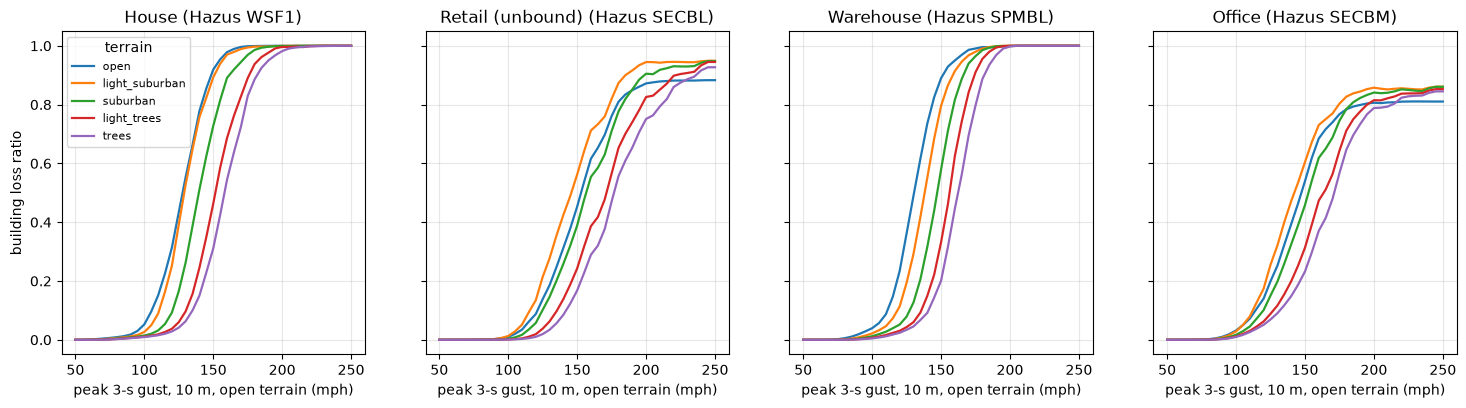

In [4]:
ords = table(f"CURVE_ORDINATES_{V2}.csv")
check = []
for r in ART["pathways"][0]["curve_records"]:
    sel = r["selector_match"]
    g = ords[(ords.reference_building_id == sel["reference_building_id"]) & (ords.hazus_terrain_class == sel["hazus_terrain_class"])]
    g = g.sort_values("peak_gust_3s_10m_open_terrain_mph")
    csv_pts = [[float(x), float(y)] for x, y in zip(g.peak_gust_3s_10m_open_terrain_mph, g.building_loss_ratio)]
    check.append({"curve_id": r["curve_id"], "points": len(r["parameters"]["points"]), "artifact = table": r["parameters"]["points"] == csv_pts})
display(pd.DataFrame(check))

fig, axes = plt.subplots(1, 4, figsize=(18, 4.2), sharey=True)
for ax, (b, g) in zip(axes, ords.groupby("reference_building_id", sort=False)):
    for t, gg in g.groupby("hazus_terrain_class", sort=False):
        ax.plot(gg.peak_gust_3s_10m_open_terrain_mph, gg.building_loss_ratio, lw=1.6, label=t)
    ax.set_title(f'{NAMES[b]} (Hazus {g.hazus_sbt.iloc[0]})')
    ax.set_xlabel("peak 3-s gust, 10 m, open terrain (mph)")
axes[0].set_ylabel("building loss ratio")
axes[0].legend(fontsize=8, title="terrain")
save(fig, "00_hazus_records_by_terrain.png")
plt.show()

## 4. Variant sensitivity

Where a Hazard profile does not state a wind characteristic, the national most-common Hazus value is used. The
sensitivity table shows what the other variants would read (for example code-built roof connections on the house,
or an old roof deck on the warehouse).

In [5]:
sens = table(f"VARIANT_SENSITIVITY_{V2}.csv")
display(sens[["reference_building_id", "variant", "role", "hazus_sbt", "terrain", "loss_ratio_100mph", "loss_ratio_120mph",
              "loss_ratio_140mph", "loss_ratio_160mph"]])

,reference_building_id,variant,role,hazus_sbt,terrain,loss_ratio_100mph,loss_ratio_120mph,loss_ratio_140mph,loss_ratio_160mph
0,RE_RES_SFD_1S_SLAB,reference (most common),reference,WSF1,open,0.0524,0.3135,0.7788,0.9786
1,RE_RES_SFD_1S_SLAB,reference (most common),reference,WSF1,suburban,0.0144,0.0925,0.5117,0.8910
2,RE_RES_SFD_1S_SLAB,roof-to-wall straps,code_built_sensitivity,WSF1,open,0.0440,0.2435,0.7235,0.9668
3,RE_RES_SFD_1S_SLAB,roof-to-wall straps,code_built_sensitivity,WSF1,suburban,0.0141,0.0676,0.2970,0.6921
4,RE_RES_SFD_1S_SLAB,"roof deck 8d @ 6""/12"" + straps",code_built_sensitivity,WSF1,open,0.0367,0.1896,0.6198,0.9335
5,RE_RES_SFD_1S_SLAB,"roof deck 8d @ 6""/12"" + straps",code_built_sensitivity,WSF1,suburban,0.0136,0.0522,0.2146,0.5344
6,RE_RES_SFD_1S_SLAB,"roof deck 8d @ 6""/6"" + straps",code_built_sensitivity,WSF1,open,0.0197,0.1170,0.5220,0.9068
7,RE_RES_SFD_1S_SLAB,"roof deck 8d @ 6""/6"" + straps",code_built_sensitivity,WSF1,suburban,0.0073,0.0262,0.1424,0.4320
8,RE_RES_SFD_1S_SLAB,"roof deck 8d @ 6""/12"", toe-nail",code_built_sensitivity,WSF1,open,0.0477,0.2900,0.7464,0.9769
9,RE_RES_SFD_1S_SLAB,"roof deck 8d @ 6""/12"", toe-nail",code_built_sensitivity,WSF1,suburban,0.0135,0.0849,0.4769,0.8625


## 5. Decisions

The decision log is shared by v0.1 and v0.2; D-TCRE-22 to D-TCRE-25 are the v0.2 changes.

In [6]:
log = decision_log(PROP / f"DECISION_LOG_{REG}.md")
display(log.groupby("status").size().rename("decisions").to_frame())
display(log)

,decisions
status,
JL decided,9
proposed,16


,id,status,decision
0,D-TCRE-01,proposed,"One cell, `tropical_cyclone_wind_real_estate`, for all three asset types; the reference building is a selector on one failure unit."
1,D-TCRE-02,proposed,"(Model v0.2: the shared IDs follow the Hazard reference profiles r1 and add `RE_COM_OFFICE_3S_SLAB`, D-TCRE-22.) Reuse the three `flood_real_estate` referen..."
2,D-TCRE-03,proposed,"Axis = peak 3-second gust at 10 m, open terrain, in mph (`tc_peak_gust_3s_10m_mph`). Saffir-Simpson category and one-minute or ten-minute sustained wind are..."
3,D-TCRE-04,proposed,"One pathway, `tropical_cyclone_wind`, that includes the windborne-debris and rain-ingress damage embedded in the source loss functions. No separate debris o..."
4,D-TCRE-05,proposed,Grain = one source-native whole-building record per reference building (and wind-characteristic combination). No separate roof failure unit in v0.1 unless s...
5,D-TCRE-06,JL decided,"JL decided — terrain is a required selector `hazus_terrain_class` with the five Hazus classes (open, light_suburban, suburban, light_trees, trees). No defau..."
6,D-TCRE-07,JL decided,"(Model v0.2: profile values replace the most-common value where the Hazard profile states one — office D-TCRE-23, warehouse roof deck D-TCRE-24.) JL decided..."
7,D-TCRE-08,proposed,"Out of scope: storm surge, waves and rainfall flooding (→ `flood_real_estate`); TC-spawned tornadoes (→ a future convective-wind × real-estate cell); conten..."
8,D-TCRE-09,proposed,"Denominator = structure replacement cost new, 100% on the one failure unit, shared with `flood_real_estate`; the per-area cost stays the shared open seam an..."
9,D-TCRE-10,proposed,"The legacy `hurricane_tropical_cyclone_wind_storm_residential` (""Climada"") and `strong_wind_small_residential` arrays are not evidence for this cell."


## 6. Parameter tiers

In [7]:
tiers = pd.DataFrame(ART["parameter_tier_table"])
cols = [c for c in ("parameter", "curve_id", "value", "tier", "status") if c in tiers.columns]
display(tiers[cols])
display(tiers.groupby("tier").size().rename("parameters").to_frame())

,parameter,curve_id,value,tier,status
0,axis_definition,all,"peak 3-second gust at 10 m, open terrain (z0 0.03 m), mph",T2_public_lab_standard_or_physics,proposed
1,axis_bridge,all,none in Damage (Hazard converts STORM 10-min wind),T2_public_lab_standard_or_physics,proposed
2,curve_ordinates_house,TCRE_RES_HAZUS_WSF1_*,"Hazus WSF1 wbID 6 building loss, 5 terrains, 50-250 mph every 5 mph",T2_public_lab_standard_or_physics,proposed
3,curve_ordinates_commercial,TCRE_COM_HAZUS_SECBL_*,"Hazus SECBL wbID 1812 building loss, 5 terrains",T2_public_lab_standard_or_physics,proposed
4,curve_ordinates_warehouse,TCRE_IND_HAZUS_SPMBL_*,"Hazus SPMBL wbID 1729 building loss, 5 terrains",T2_public_lab_standard_or_physics,proposed
5,building_type_house,TCRE_RES_HAZUS_WSF1_*,"WSF1 (CONUS, CaseID 1)",T2_public_lab_standard_or_physics,proposed
6,building_type_commercial,TCRE_COM_HAZUS_SECBL_*,SECBL (identical to MECBL),T3_engineering_proxy_or_adjacent_empirical,proposed
7,building_type_warehouse,TCRE_IND_HAZUS_SPMBL_*,"SPMBL (> 50,000 ft2)",T3_engineering_proxy_or_adjacent_empirical,proposed
8,wind_characteristics_house,TCRE_RES_HAZUS_WSF1_*,"gable; no SWR; 6d @ 6""/12""; toe-nail; no garage; no shutters; shingle",T4_placeholder_or_expert_judgment,proposed
9,wind_characteristics_commercial,TCRE_COM_HAZUS_SECBL_*,BUR; low window area; debris environment B; standard metal deck; no shutters,T4_placeholder_or_expert_judgment,proposed


,parameters
tier,
T2_public_lab_standard_or_physics,12
T3_engineering_proxy_or_adjacent_empirical,2
T4_placeholder_or_expert_judgment,4


## 7. What is still open

- House roof nailing and roof-to-wall connections depend on the local building code; a code or design-wind zone per
  cell from Hazard would let the house use the code-built variant where it applies.
- Hazus commercial records read slightly higher in light-suburban than open terrain (a source feature, kept).
- Tree fall on the house is a separate Hazus add-on, withheld (not zero).

In [8]:
cap = ART["capability_declaration"]
rows = []
for pc in cap["pathway_capabilities"]:
    rows.append({"pathway": pc["pathway_id"], "failure-unit DR": pc["failure_unit_scalar_dr"],
                 "scenario loss": pc["scenario_loss_given_value_basis"], "spread": pc["curve_intrinsic_spread"],
                 "withheld units": ", ".join(w["failure_unit_id"] for w in pc.get("withheld_failure_units", []))})
display(pd.DataFrame(rows))
print("Annual and tail metrics:", cap["consumer_annual_metrics"]["status_before_promotion"],
      "(owner:", cap["consumer_annual_metrics"]["computation_owner"] + ")")
print("Promotion gate:", cap["promotion_gate"]["status"])
for item in cap["promotion_gate"]["required_before_canonical_use"]:
    print("  -", item)

,pathway,failure-unit DR,scenario loss,spread,withheld units
0,tropical_cyclone_wind,conditional,withheld,not_carried,TCRE_BUILDING_CONTENTS


Annual and tail metrics: withheld_noncanonical_proposal (owner: downstream_consumer)
Promotion gate: blocked
  - owner accepts scope D-TCRE-01 to D-TCRE-05 and D-TCRE-08 to D-TCRE-13, and selections D-TCRE-17 to D-TCRE-25
  - consumer value qualification of each reference budget (shared with flood_real_estate)
  - Hazard supplies a terrain class per building location
  - independent review of the package
